# Data import
Za početak importamo datasetove. Korišteni datasetovi su preuzeti iz istraživanja pronađenog na internetu. U dokumentaciji se nalazi detaljna usporedba dobivenih rezultata s onima iz tog istraživanja, kao i poveznice na originalni istraživački rad.
Dokumentacija također sadrži detaljnu analizu svih dobivenih rezultata, kao i opis svakog koraka pri treniranju modela.


In [1]:
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler, MinMaxScaler


In [2]:
print("Current Working Directory:", os.getcwd())


# Load the datasets
mat_data = pd.read_csv('../../student/student-mat.csv', sep=';')
por_data = pd.read_csv('../../student/student-por.csv', sep=';')

# View the first few rows
print(mat_data.head())
print(por_data.head())

Current Working Directory: /Users/enesek/Documents/projekt-R/testiranje/regresijski_modeli/combined
  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        6   5   6   6  
1      5        3      3     1     1      3        4   5   5   6  
2      4        3      2     2     3      3       10   7   8  10  
3      3        2      2     1     1      5        2  15  14  15  
4      4        3      2     1     2      5        4   6  10  10  

[5 rows x 

In [3]:
print(mat_data.describe())
print(por_data.describe())

              age        Medu        Fedu  traveltime   studytime    failures  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean    16.696203    2.749367    2.521519    1.448101    2.035443    0.334177   
std      1.276043    1.094735    1.088201    0.697505    0.839240    0.743651   
min     15.000000    0.000000    0.000000    1.000000    1.000000    0.000000   
25%     16.000000    2.000000    2.000000    1.000000    1.000000    0.000000   
50%     17.000000    3.000000    2.000000    1.000000    2.000000    0.000000   
75%     18.000000    4.000000    3.000000    2.000000    2.000000    0.000000   
max     22.000000    4.000000    4.000000    4.000000    4.000000    3.000000   

           famrel    freetime       goout        Dalc        Walc      health  \
count  395.000000  395.000000  395.000000  395.000000  395.000000  395.000000   
mean     3.944304    3.235443    3.108861    1.481013    2.291139    3.554430   
std      0.896659    0.9988

# Encoding the data
Binarne varijable kodirane su LabelEncoder metodom
Kategoričke varijable one-hot encodig metodom
Numeričke vrijednosti skalirane su minmax skalerom

In [4]:
# combine the data
combined_data = pd.concat([mat_data, por_data], ignore_index=True)

In [5]:
from sklearn.preprocessing import LabelEncoder

# encoding the binary features
binary_features = ['school', 'sex', 'address', 'famsize', 'Pstatus', 
                   'schoolsup', 'famsup', 'paid', 'activities', 
                   'nursery', 'higher', 'internet', 'romantic']

label_encoder = LabelEncoder()
for feature in binary_features:
    combined_data[feature] = label_encoder.fit_transform(combined_data[feature])


# one-hot endocing the categorical features
categorical_features = ['Mjob', 'Fjob', 'reason', 'guardian']

combined_data = pd.get_dummies(combined_data, columns=categorical_features, drop_first=True)

# normalizing numeric features using min-max scaling
numeric_features = ['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 
                    'failures', 'famrel', 'freetime', 'goout', 'Dalc', 
                    'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

scaler = MinMaxScaler()
combined_data[numeric_features] = scaler.fit_transform(combined_data[numeric_features])



# Training the Linear Regression Model


In [6]:
# Selecting the features and targer variable
# For mat_data or por_data individually
X = combined_data.drop(columns=['G3'])  # Drop the target variable
y = combined_data['G3']  # Target variable (G3)


Za treniranje modela linearne regresije potrebno je prvo podijeliti vrijednosti u dvije skupine. U ovom primjeru 20% korišteno je za testiranje, a 80% za treniranje

In [7]:
# Spliting the data = 80% training, 20% testing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt


# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)


In [8]:
# Train the linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [9]:
# Make predictions
y_pred = model.predict(X_test)

Nakon treniranja modela koristimo onih 20% kako bi testirali model i predvidjeli podatke. Mean Squared Error i R-suqared nam govore o vjerodostojnosti modela.

In [10]:
# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Print evaluation metrics
print(f"Mean Squared Error: {mse}")
print(f"R-squared: {r2}")


Mean Squared Error: 0.007669573681632214
R-squared: 0.7932225454839706


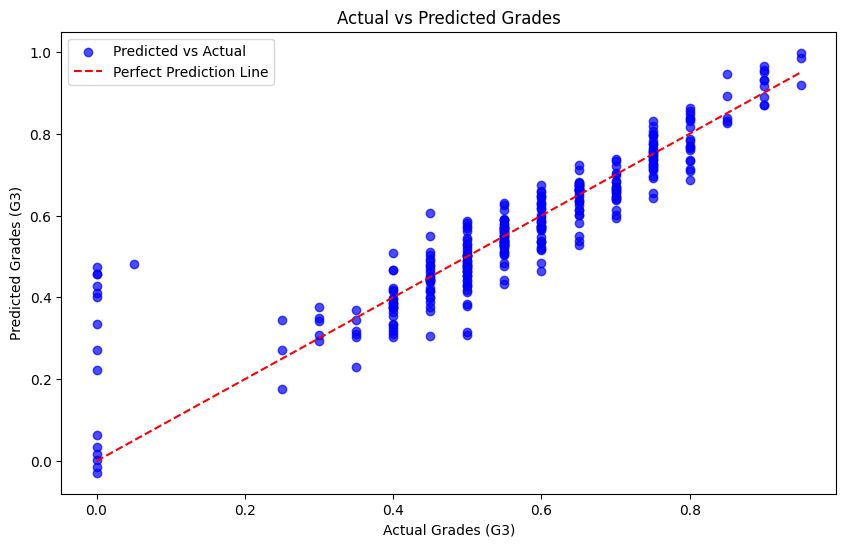

In [11]:
# Plot actual vs predicted grades
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.7, color='b', label='Predicted vs Actual')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='r', linestyle='--', label='Perfect Prediction Line')
plt.xlabel("Actual Grades (G3)")
plt.ylabel("Predicted Grades (G3)")
plt.title("Actual vs Predicted Grades")
plt.legend()
plt.show()



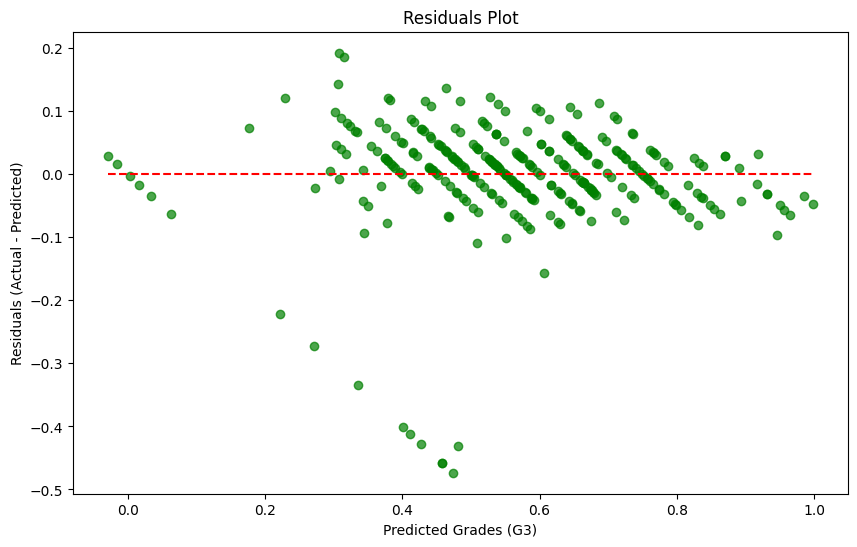

In [12]:
# Residuals Plot
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.7, color='g')
plt.hlines(y=0, xmin=y_pred.min(), xmax=y_pred.max(), color='r', linestyle='--')
plt.xlabel("Predicted Grades (G3)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residuals Plot")
plt.show()

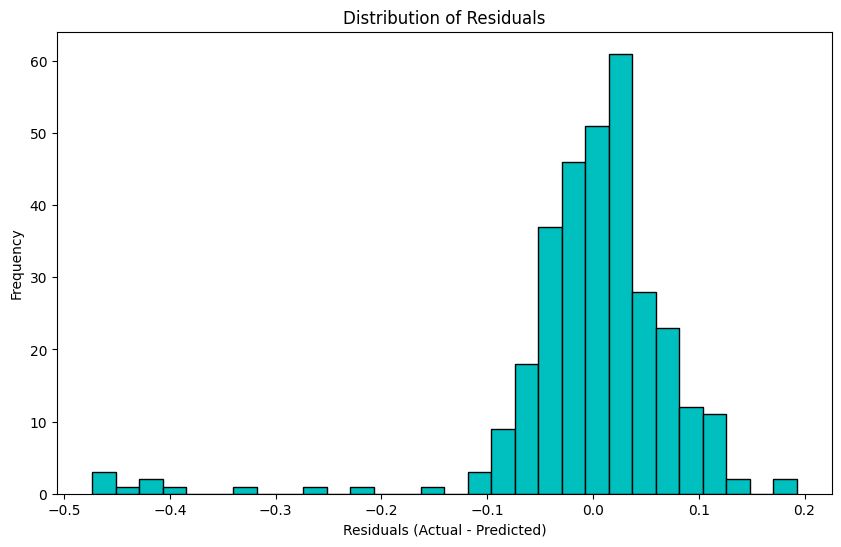

In [13]:
# Distribution of Residuals
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=30, color='c', edgecolor='black')
plt.xlabel("Residuals (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")
plt.show()


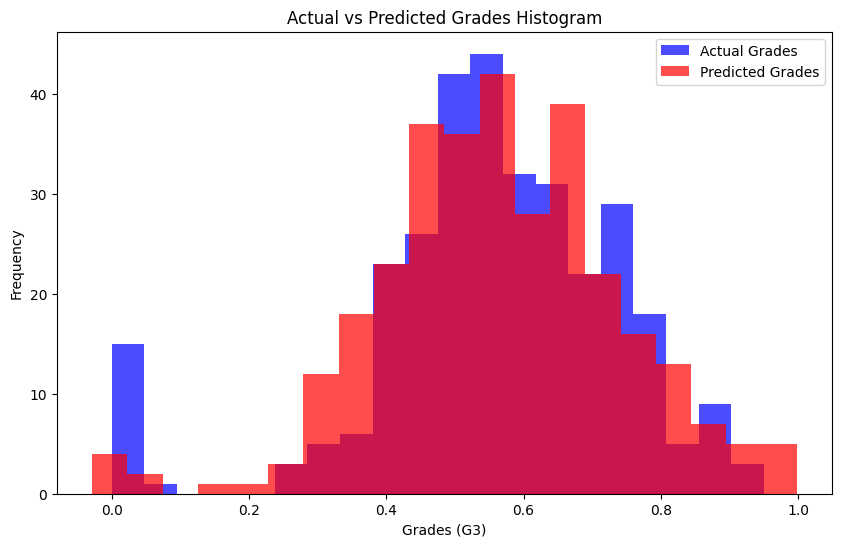

In [14]:
# Actual vs Predicted Grades Histogram
plt.figure(figsize=(10, 6))
plt.hist(y_test, bins=20, alpha=0.7, label='Actual Grades', color='b')
plt.hist(y_pred, bins=20, alpha=0.7, label='Predicted Grades', color='r')
plt.xlabel("Grades (G3)")
plt.ylabel("Frequency")
plt.title("Actual vs Predicted Grades Histogram")
plt.legend()
plt.show()
